# FashionMNIST Classification with a Simple CNN

## Project Overview

This notebook implements and evaluates a **Convolutional Neural Network (CNN)** for image classification on the FashionMNIST dataset using PyTorch. The architecture follows a straightforward `nn.Sequential` design consisting of three convolutional blocks and a fully connected classification head.

**Objectives**
- Build an interpretable CNN baseline for classifying **28 × 28 grayscale images** into **10 clothing categories**.
- Track training and validation performance, select the best model checkpoint, and analyze prediction errors.
- Support reproducible experiments by recording model settings, training metrics, and visualizations separately for each run.
- Enable comparison with the project's MLP baseline using experimentally measured results.

**Scope:** This implementation uses standard convolutions rather than depthwise-separable convolutions or pretrained backbones. It prioritizes architectural simplicity; lower parameter count or superior accuracy relative to other models is **not assumed**. The test set is reserved for final evaluation.

## 1. Environment and Data Preparation

Import the required libraries and reuse the project's existing `src/data.py` and `src/metrics.py` utilities. The notebook locates the FashionMNIST project directory and creates the training, validation, and test data loaders.

FashionMNIST contains single-channel images of shape **(1, 28, 28)**. A fixed random seed is used to improve reproducibility, and computation runs on CUDA when available, otherwise on CPU.

In [3]:
import json, sys, random, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import transforms

root = Path.cwd().resolve()
while not (root / 'src' / 'data.py').is_file():
    if (root / 'practice_1_fashionmnist' / 'src' / 'data.py').is_file():
        root = root / 'practice_1_fashionmnist'
        break
    if root.parent == root:
        raise FileNotFoundError('Mở notebook trong thư mục project hoặc workspace chứa practice_1_fashionmnist')
    root = root.parent
sys.path.insert(0, str(root / 'src'))
from data import build_loaders
from metrics import evaluate

SETTINGS = dict(seed=42, epochs=40, batch_size=64, lr=0.001,
                weight_decay=1e-3, dropout=0.5, patience=12)
DATA_SETTINGS = dict(seed=42, val_size=0.1, batch_size=SETTINGS['batch_size'])

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

set_seed(SETTINGS['seed'])
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
train_loader, val_loader, test_loader = build_loaders(DATA_SETTINGS)

# Data augmentation - training only
train_transform = transforms.Compose([
    transforms.RandomCrop(28, padding=2),
    transforms.RandomHorizontalFlip(p=0.5),
])

class AugmentedDataset(torch.utils.data.Dataset):
    def __init__(self, dataset, transform):
        self.dataset = dataset
        self.transform = transform

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, index):
        image, label = self.dataset[index]
        return self.transform(image), label

train_loader = DataLoader(
    AugmentedDataset(train_loader.dataset, train_transform),
    batch_size=SETTINGS["batch_size"],
    shuffle=True
)

print('Device:', device)
print('Train / validation / test:', *(len(x.dataset) for x in (train_loader, val_loader, test_loader)))

Device: cuda
Train / validation / test: 54000 6000 10000


## 2. CNN Architecture

The feature extractor contains **three convolutional blocks**, each consisting of two **3 × 3 convolutions**, with Batch Normalization and ReLU activation after each convolution. A **2 × 2 max-pooling** operation at the end of every block reduces the spatial resolution from **28 × 28 → 14 × 14 → 7 × 7 → 3 × 3**.

| Component | Output dimensions (channels × height × width) |
|---|---|
| Input | 1 × 28 × 28 |
| Convolutional block 1 + pooling | 32 × 14 × 14 |
| Convolutional block 2 + pooling | 64 × 7 × 7 |
| Convolutional block 3 + pooling | 128 × 3 × 3 |
| Flatten | 1,152 features |
| Classification head | 256 hidden features → 10 logits |

The classifier uses `Flatten → LazyLinear(256) → ReLU → Dropout(0.4) → Linear(10)`. The lazy layer is initialized through a dummy forward pass before its parameters are counted and the optimizer is created. The first convolution accepts **1 input channel**, matching the grayscale FashionMNIST images.

In [4]:
# Kiến trúc viết trực tiếp bằng nn.Sequential, không có SepConv.
def make_model(dropout=0.5):
    return nn.Sequential(
        # Block 1
        nn.Conv2d(1, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
        nn.Conv2d(32, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
        nn.MaxPool2d(2),

        # Block 2
        nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
        nn.Conv2d(64, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
        nn.MaxPool2d(2),

        # Block 3
        nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
        nn.Conv2d(128, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
        nn.MaxPool2d(2),

        # Classifier
        nn.Flatten(),
        nn.LazyLinear(256), nn.ReLU(), nn.Dropout(dropout),
        nn.Linear(256, 10),
    )

model = make_model(SETTINGS['dropout']).to(device)
# Khởi tạo LazyLinear trước khi đếm parameters và tạo optimizer.
model.eval()
with torch.no_grad():
    output_shape = model(torch.zeros(2, 1, 28, 28, device=device)).shape
model.train()
parameters = sum(p.numel() for p in model.parameters() if p.requires_grad)
assert output_shape == (2, 10)
print('Trainable parameters:', parameters, '| Output shape:', tuple(output_shape))
print(model)

Trainable parameters: 585066 | Output shape: (2, 10)
Sequential(
  (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (2): ReLU()
  (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (5): ReLU()
  (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (7): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (8): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (9): ReLU()
  (10): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (11): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (12): ReLU()
  (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (14): Conv2d(64, 128, kern

## 3. Model Training and Checkpoint Selection

Training uses **Cross-Entropy Loss** for multiclass classification, the **AdamW** optimizer for parameter updates, and a **CosineAnnealingLR** scheduler to adjust the learning rate over time.

The notebook records loss and accuracy for each epoch and selects a checkpoint according to the following rules:

1. Highest **validation accuracy** takes priority.
2. In the event of a tie, lower **validation loss** takes priority.
3. **Early stopping** ends training if validation performance does not improve within the configured patience window.

Every execution saves its settings, per-epoch metrics, and best model weights to a new directory under `outputs/cnn_runs/lan_N/`, preserving previous experiments.

In [5]:
set_seed(SETTINGS['seed'])
model = make_model(SETTINGS['dropout']).to(device)
model.eval()
with torch.no_grad():
    model(torch.zeros(1, 1, 28, 28, device=device))
model.train()
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=SETTINGS['lr'], weight_decay=SETTINGS['weight_decay'])
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=SETTINGS['epochs'])

runs = root / 'outputs' / 'cnn_runs'
runs.mkdir(parents=True, exist_ok=True)
i = 1
while True:
    folder = runs / f'lan_{i}'
    try:
        folder.mkdir()  # Atomic creation; never overwrite a previous experiment
        break
    except FileExistsError:
        i += 1
(folder / 'config.json').write_text(json.dumps(dict(settings=SETTINGS, data=DATA_SETTINGS, parameters=parameters,
    architecture=str(model), selection='max_val_accuracy_then_min_val_loss'), indent=2), encoding='utf-8')
history, best_score, best_epoch, no_improve = [], (-1.0, float('-inf')), 0, 0
start = time.perf_counter()
for epoch in range(1, SETTINGS['epochs'] + 1):
    model.train()
    total_loss, correct = 0., 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(labels)
        correct += (logits.argmax(1) == labels).sum().item()
    val = evaluate(model, val_loader, device)
    row = dict(epoch=epoch, train_loss=total_loss / len(train_loader.dataset),
               train_accuracy=correct / len(train_loader.dataset),
               val_loss=val['loss'], val_accuracy=val['accuracy'],
               lr=optimizer.param_groups[0]['lr'])
    history.append(row)
    score = (val['accuracy'], -val['loss'])
    if score > best_score:
        best_score, best_epoch, no_improve = score, epoch, 0
        torch.save(dict(model_state=model.state_dict(), settings=dict(SETTINGS),
             data_config=dict(DATA_SETTINGS), validation=val, epoch=epoch,
             architecture='SimpleSequentialCNN', parameters=parameters), folder / 'best.pt')
    else:
        no_improve += 1
    print(f"Epoch {epoch:02d}/{SETTINGS['epochs']} | train={row['train_accuracy']:.2%} "
          f"| val={val['accuracy']:.2%} | val_loss={val['loss']:.4f} "
          f"| best={best_epoch} | lr={row['lr']:.6f}", flush=True)
    (folder / 'metrics.json').write_text(json.dumps(history, indent=2), encoding='utf-8')
    scheduler.step()
    if no_improve >= SETTINGS['patience']:
        print('Early stopping: validation did not improve')
        break
print(f'Finished: {folder} | best_epoch={best_epoch} | seconds={time.perf_counter()-start:.1f}')

Epoch 01/40 | train=79.94% | val=87.73% | val_loss=0.3231 | best=1 | lr=0.001000
Epoch 02/40 | train=87.20% | val=90.85% | val_loss=0.2326 | best=2 | lr=0.000998
Epoch 03/40 | train=88.89% | val=89.53% | val_loss=0.2726 | best=2 | lr=0.000994
Epoch 04/40 | train=90.12% | val=90.37% | val_loss=0.2483 | best=2 | lr=0.000986
Epoch 05/40 | train=90.73% | val=91.82% | val_loss=0.2145 | best=5 | lr=0.000976
Epoch 06/40 | train=91.47% | val=92.70% | val_loss=0.1960 | best=6 | lr=0.000962
Epoch 07/40 | train=91.78% | val=93.28% | val_loss=0.1852 | best=7 | lr=0.000946
Epoch 08/40 | train=92.28% | val=92.90% | val_loss=0.1857 | best=7 | lr=0.000926
Epoch 09/40 | train=92.64% | val=93.10% | val_loss=0.1857 | best=7 | lr=0.000905
Epoch 10/40 | train=92.95% | val=93.17% | val_loss=0.1875 | best=7 | lr=0.000880
Epoch 11/40 | train=93.19% | val=93.75% | val_loss=0.1768 | best=11 | lr=0.000854
Epoch 12/40 | train=93.57% | val=93.72% | val_loss=0.1760 | best=11 | lr=0.000825
Epoch 13/40 | train=93.75%

## 4. Best-Checkpoint Evaluation

Load the saved checkpoint and evaluate the selected model on the training and validation subsets in **evaluation mode** (`model.eval()`). This ensures the reported results correspond to the selected checkpoint rather than the final training epoch. The resulting metrics and best epoch are saved to `result.json` for later review.

In [6]:
saved = torch.load(folder / 'best.pt', map_location=device, weights_only=True)
model = make_model(saved['settings']['dropout']).to(device)
model.eval()
with torch.no_grad():
    model(torch.zeros(1, 1, 28, 28, device=device))
model.load_state_dict(saved['model_state'])
model.eval()
train_eval = DataLoader(train_loader.dataset, batch_size=256, shuffle=False)
scores = {'train': evaluate(model, train_eval, device),
          'validation': evaluate(model, val_loader, device)}
print('Best epoch:', saved['epoch'], '| Parameters:', saved['parameters'])
print(pd.DataFrame(scores).T.to_string())
assert abs(scores['validation']['accuracy'] - saved['validation']['accuracy']) < 1e-10
(folder / 'result.json').write_text(json.dumps(dict(scores=scores, best_epoch=saved['epoch']), indent=2), encoding='utf-8')

Best epoch: 39 | Parameters: 585066
                loss  accuracy    count
train       0.058226  0.978167  54000.0
validation  0.163953  0.953333   6000.0


276

## 5. Learning Curves and Confusion Matrix

Visualize the evolution of **training and validation loss** and **accuracy** across epochs. The learning curves highlight the selected checkpoint and help assess convergence and possible overfitting.

A **validation confusion matrix** summarizes class-level prediction behavior: rows represent ground-truth classes, and columns represent predicted classes. The notebook exports both the visualization and the underlying counts for reproducible error analysis.

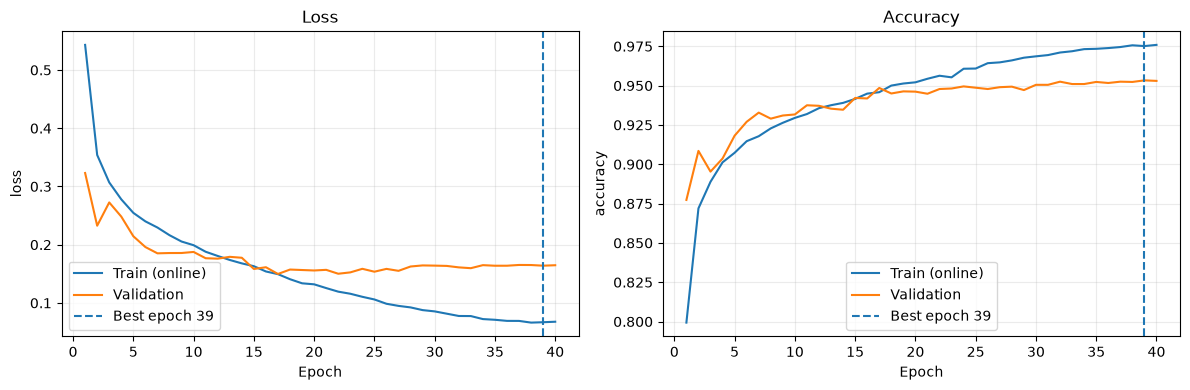

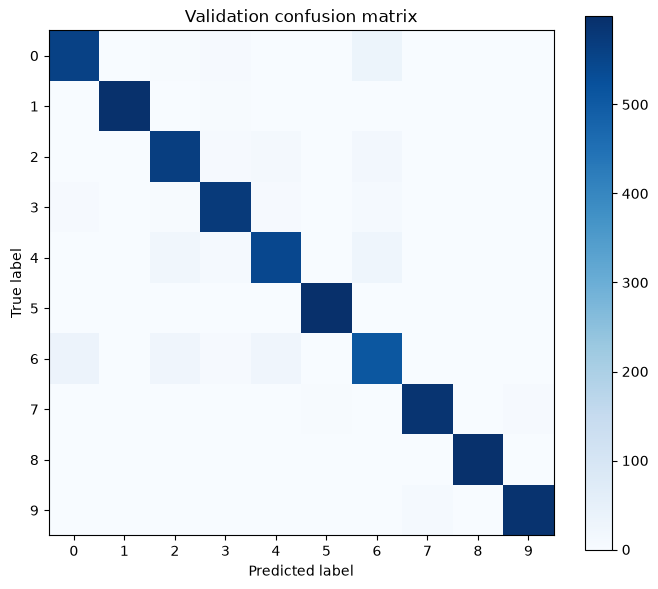

348

In [7]:
df = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for key, axis in [('loss', axes[0]), ('accuracy', axes[1])]:
    axis.plot(df.epoch, df['train_' + key], label='Train (online)')
    axis.plot(df.epoch, df['val_' + key], label='Validation')
    axis.axvline(best_epoch, linestyle='--', label=f'Best epoch {best_epoch}')
    axis.set(title=key.title(), xlabel='Epoch', ylabel=key)
    axis.grid(alpha=.25); axis.legend()
fig.tight_layout(); fig.savefig(folder / 'curves.png', dpi=130); plt.show()

confusion = torch.zeros(10, 10, dtype=torch.int64)
with torch.no_grad():
    for images, labels in val_loader:
        pred = model(images.to(device)).argmax(1).cpu()
        for true, guess in zip(labels, pred): confusion[int(true), int(guess)] += 1
assert confusion.sum().item() == len(val_loader.dataset)
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(confusion.numpy(), cmap='Blues')
ax.set(xlabel='Predicted label', ylabel='True label', title='Validation confusion matrix')
ax.set_xticks(range(10)); ax.set_yticks(range(10))
fig.colorbar(im, ax=ax); fig.tight_layout()
fig.savefig(folder / 'confusion_validation.png', dpi=130); plt.show()
(folder / 'confusion_validation.json').write_text(json.dumps(confusion.tolist()), encoding='utf-8')

## 6. MLP Baseline Comparison and Optional Test Evaluation

When `outputs/run_review.json` is available, the notebook reads existing MLP validation metrics and displays them alongside the CNN's measured validation performance. Report the parameter count and accuracy of each model as separate comparison criteria; this standard CNN architecture is **not guaranteed to use fewer parameters than the MLP**.

Final testing is intentionally **disabled by default** (`RUN_FINAL_TEST = False`). Enable it only after model selection and hyperparameter decisions are complete. The test set should not be used to optimize the model or select checkpoints.

In [8]:
review_path = root / 'outputs' / 'run_review.json'
if review_path.exists():
    review = json.loads(review_path.read_text(encoding='utf-8'))
    entries = []
    for run in review.get('runs', []):
        if run.get('run') in {'lan_10', 'lan_11', 'lan_12'}:
            val = run.get('splits', {}).get('validation', {})
            entries.append(dict(model='MLP ' + run['run'], parameters=None,
                                val_accuracy=val.get('accuracy'), val_loss=val.get('loss')))
    entries.append(dict(model='CNN ' + folder.name, parameters=parameters,
                        val_accuracy=scores['validation']['accuracy'], val_loss=scores['validation']['loss']))
    print(pd.DataFrame(entries).to_string(index=False))
else:
    print('Không thấy run_review.json: chỉ báo cáo CNN, không tự tạo số liệu MLP.')

RUN_FINAL_TEST = True
if RUN_FINAL_TEST:
    scores['test'] = evaluate(model, test_loader, device)
    print('FINAL TEST:', scores['test'])
    (folder / 'result.json').write_text(json.dumps(dict(scores=scores, best_epoch=saved['epoch']), indent=2), encoding='utf-8')

     model  parameters  val_accuracy  val_loss
MLP lan_10         NaN      0.913333  0.277989
MLP lan_11         NaN      0.914833  0.308205
MLP lan_12         NaN      0.917333  0.299211
 CNN lan_6    585066.0      0.953333  0.163953
FINAL TEST: {'loss': 0.1850115954786539, 'accuracy': 0.9449, 'count': 10000}


## 7. Intermediate Feature-Map Visualization

Inspect activation maps from the last ReLU layer of the third convolutional block, before the final max-pooling operation. These visualizations provide a qualitative view of the network's learned image representations.

**Interpretation note:** Feature maps are intermediate activations, not class probabilities, and individual channels should not be treated as definitive explanations of the model's predictions.

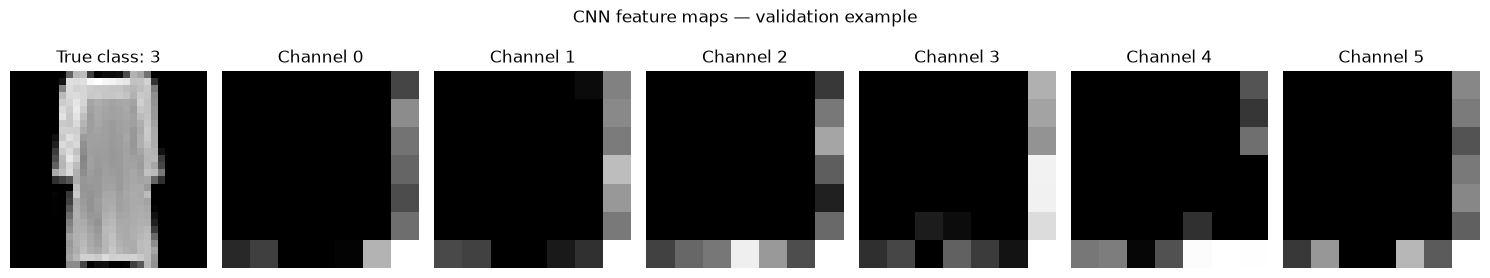

In [9]:
# Phần đầu của Sequential (index 0..19) kết thúc tại ReLU cuối Block 3.
image, label = val_loader.dataset[0]
model.eval()
with torch.no_grad():
    activations = model[:20](image.unsqueeze(0).to(device)).cpu()[0]
fig, axes = plt.subplots(1, 7, figsize=(15, 3))
axes[0].imshow(image[0], cmap='gray')
axes[0].set_title(f'True class: {int(label)}')
axes[0].axis('off')
for channel, ax in enumerate(axes[1:]):
    ax.imshow(activations[channel], cmap='gray')
    ax.set_title(f'Channel {channel}')
    ax.axis('off')
fig.suptitle('CNN feature maps — validation example')
fig.tight_layout()
fig.savefig(folder / 'backbone_features.png', dpi=130)
plt.show()